[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/padillacm/IA-practice/blob/master/agent-observability-course/10_grafana/10_grafana.ipynb)

# Módulo 10 · Grafana: dashboards como código, navegación entre señales y alertas básicas

| | |
|---|---|
| **Nivel** | 🟡 Intermedio |
| **Duración estimada** | ≈ 4 h 30 min (lección ≈ 3 h + proyecto ≈ 1 h 30 min) |
| **Servicios de Compose** | `core` + `metrics`: `docker compose --profile core --profile metrics up -d` (≈ 0,45 GB de RAM en reposo; ≈ 1 GB con tráfico). **Sin Docker** las partes que necesitan Grafana se saltan y el JSON/YAML se valida en local |
| **Prerrequisitos** | Módulo 07 (TraceQL), 08 (LogQL y `trace_id` como *structured metadata*) y 09 (métricas, PromQL, exemplars); `setup_telemetry` (módulo 03) |
| **Hilo conductor** | Todo lo que SupportOps emite (trazas, logs, métricas) se convierte en **una pantalla** que un on-call entiende a las 3 de la mañana: «Salud del agente» |

> 🗺️ **Ruta núcleo vs ampliación.** Núcleo (≈ 2 h): secciones 1, 2, 5, 6 y 7. Ampliación (≈ 1 h): variables y `$__rate_interval` (4), alertas (8) y el ecosistema «como código» (3).

## Objetivos de aprendizaje

Al terminar esta lección podrás:

1. **Describir** la arquitectura de Grafana (datasources, dashboards, alerting) y **explicar** por qué un dashboard debe responder una pregunta concreta.
2. **Leer y escribir** el JSON de un dashboard (paneles, `gridPos`, targets, `fieldConfig`, variables, enlaces) y **provisionarlo** desde un archivo.
3. **Generar** dashboards con código (determinista, revisable en git) y **validarlos** (higiene + ejecutar cada consulta contra Grafana).
4. **Usar variables** (consulta, personalizada, intervalo, texto) y **calcular** `$__rate_interval` a partir del intervalo de *scrape*.
5. **Elegir la visualización** para cada señal (series, *stat*, mapa de calor con exemplars, tabla de trazas, panel de logs).
6. **Conectar las tres señales**: exemplar → traza → logs → métricas, con los enlaces del datasource y *data links* de los paneles; recorrer el camino a mano y en el navegador.
7. **Definir alertas aprovisionadas** (consulta → *reduce* → umbral, `for`, `noDataState`, etiquetas, anotaciones, política de notificación) y **verificar** su ciclo Normal → Pending → Firing.
8. **Construir** el dashboard «Salud del agente» de SupportOps con navegación entre señales.

## 🔁 Conexión con módulos anteriores

<details>
<summary>1 · (Módulo 09) ¿Por qué `histogram_quantile(0.95, sum by (le) (rate(x_bucket[1m])))` y no `avg(histogram_quantile(...))` de las series?</summary>

Los percentiles no se promedian: se suman primero los contadores de bucket de todas las series (`sum by (le)`) y el percentil se calcula sobre la suma. Promediar percentiles de subgrupos da un número que no es el percentil del conjunto (en el módulo 09 salió ≈ 5 s frente a ≈ 9 s).

</details>

<details>
<summary>2 · (Módulo 08) En Loki, ¿`trace_id` es una etiqueta de índice? ¿Cómo se filtra por él?</summary>

No: es *structured metadata*. Se filtra **después** del selector de streams: `{service_name="supportops-agent"} | trace_id="<id>"`. Si fuera etiqueta de índice crearía un stream por traza (cardinalidad explosiva).

</details>

<details>
<summary>3 · (Módulo 09) Un exemplar no aparece en Grafana. Cita tres comprobaciones.</summary>

Que haya tráfico reciente; que la medición se registrara dentro de un span *sampled*; que el Collector exponga OpenMetrics (`enable_open_metrics`) y Prometheus guarde exemplars (`exemplar-storage`); que el datasource tenga `exemplarTraceIdDestinations` y la consulta del panel `exemplar: true`; que la traza exista en Tempo.

</details>

In [1]:
# Instala el paquete del curso (editable) con extras de gráficos. Sirve en local y en Colab (clona el repo si hace falta).
import pathlib, subprocess, sys

def _find_root():
    for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (p / "pyproject.toml").exists() and (p / "supportops").is_dir():
            return p
    return None

ROOT = _find_root()
if ROOT is None:  # p. ej. Google Colab: el notebook se abre sin el repo
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/padillacm/IA-practice", "/content/IA-practice"], check=True)
    ROOT = pathlib.Path("/content/IA-practice/agent-observability-course")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", f"{ROOT}[viz,otel]"], check=True)
print("Curso en:", ROOT)

Curso en: /home/user/IA-practice/agent-observability-course


In [2]:
import os
os.environ.setdefault("LLM_PROVIDER", "mock")          # mock = determinista, sin coste, sin API keys
import json, math, time, collections, pathlib, hashlib, copy, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from supportops import *                                 # SupportAgent, generate_tickets, check_stack, Incident, ...
from supportops import viz, sample_data, backends
from supportops.telemetry import setup_telemetry, OTelInstrumentor
from supportops.otel_metrics import *                    # MetricsInstrumentor, run_live, prom_instant, prom_range, tempo_spans, ...
from supportops import dashkit as dk                     # dashboards como código
viz.apply_style()
pd.set_option("display.width", 150); pd.set_option("display.max_colwidth", 100)
SEED = 42
FAST_DEV_RUN = True   # True: tráfico en vivo corto (~110 s). False: más largo

STACK = check_stack("core+metrics")
LIVE = not STACK.degraded
print("\nModo:", "COMPLETO (stack real)" if LIVE else "DEGRADADO (sin Grafana: se valida el JSON/YAML en local y se muestran capturas pregrabadas)")
IMG = ROOT / "10_grafana" / "img"; DASH_DIR = ROOT / "stack" / "grafana" / "dashboards"; PROV = ROOT / "stack" / "grafana" / "provisioning"

Estado del stack:
  [OK  ] collector  http://localhost:13133/ (requerido)
  [OK  ] tempo      http://localhost:3200 (requerido)
  [OK  ] loki       http://localhost:3100 (requerido)
  [OK  ] grafana    http://localhost:3000 (requerido)
  [OK  ] prometheus http://localhost:9090 (requerido)
  [----] pyroscope  http://localhost:4040

Todo lo requerido está arriba: modo completo.

Modo: COMPLETO (stack real)


---
# 1 · Intuición: un dashboard es una **pregunta**, no un álbum de gráficos

Grafana no almacena telemetría: es un **frontend de consultas**. Cada panel es *una consulta a un datasource + cómo dibujarla*. Los datos viven en Prometheus (métricas), Loki (logs) y Tempo (trazas), que ya configuraste en el módulo 00. Lo que añade Grafana es: **composición** (varias señales en una pantalla), **navegación** (de un punto de una gráfica a la traza o a los logs) y **alertas**.

| Si vienes de… | Un dashboard de Grafana es… |
|---|---|
| **ML** | El panel de experimentos (TensorBoard / W&B): curvas comparables, filtros por *run* → aquí, **variables** por servicio/tier |
| **Backend** | La pantalla de RED del servicio: tasa, errores, duración, con *drill-down* a la traza del peor caso |
| **SRE** | La **pantalla del on-call**: arriba, «¿estoy bien?»; abajo, «¿dónde?» y «¿por qué?»; enlazada desde la alerta |

La guía de buenas prácticas de dashboards de Grafana lo resume en tres ideas que seguiremos: **(1)** *un dashboard debe contar una historia o responder una pregunta* (de lo general a lo específico); **(2)** *debe reducir la carga cognitiva*, no aumentarla; **(3)** *alerta sobre síntomas, no sobre causas*: RED mide la experiencia del usuario (síntomas) y USE los recursos (causas). Y su «modelo de madurez» describe lo que haremos: **variables** en vez de dashboards copiados, **jerarquía con *drill-down***, **JSON en control de versiones**, **sin edición en el navegador**, y dashboards generados con scripts (Grafonnet, grafanalib…).

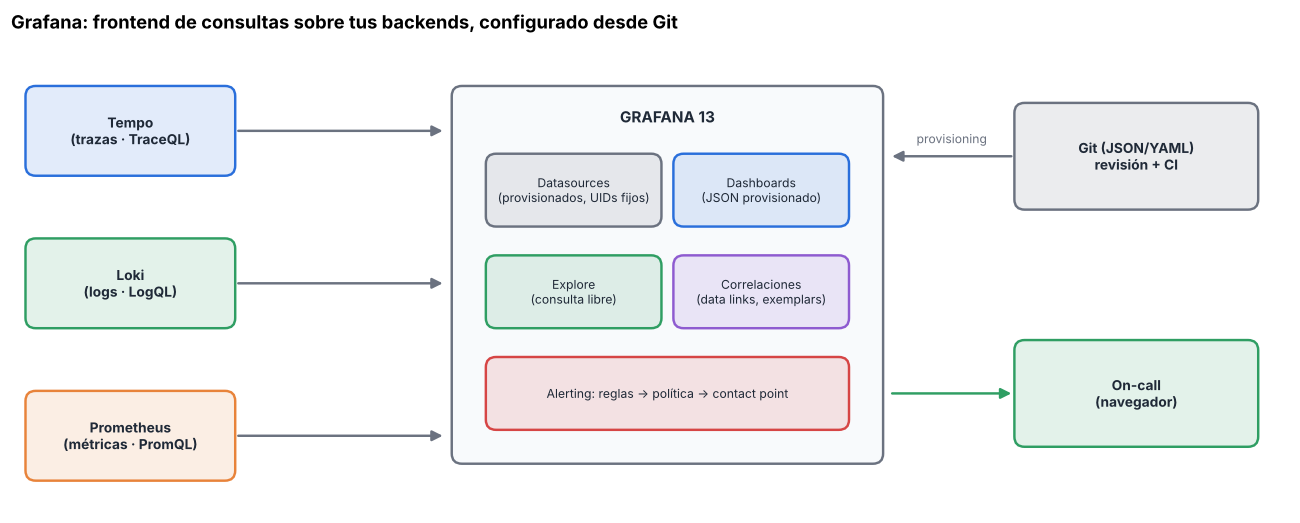

In [3]:
fig, ax = viz.canvas(15, 5.6, xlim=(0, 150), ylim=(0, 56))
P = viz.PALETTE
src = [viz.box(ax, 2, 40, 24, 10, "Tempo\n(trazas · TraceQL)", P["traces"], bold=True),
       viz.box(ax, 2, 22, 24, 10, "Loki\n(logs · LogQL)", P["logs"], bold=True),
       viz.box(ax, 2, 4, 24, 10, "Prometheus\n(métricas · PromQL)", P["metrics"], bold=True)]
gf = viz.box(ax, 52, 6, 50, 44, "", P["neutral"], fc="#f8fafc")
ax.text(77, 46, "GRAFANA 13", ha="center", fontweight="bold", color=P["dark"])
parts = [viz.box(ax, 56, 34, 20, 8, "Datasources\n(provisionados, UIDs fijos)", P["neutral"], fontsize=8),
         viz.box(ax, 78, 34, 20, 8, "Dashboards\n(JSON provisionado)", P["traces"], fontsize=8),
         viz.box(ax, 56, 22, 20, 8, "Explore\n(consulta libre)", P["logs"], fontsize=8),
         viz.box(ax, 78, 22, 20, 8, "Correlaciones\n(data links, exemplars)", P["profiles"], fontsize=8),
         viz.box(ax, 56, 10, 42, 8, "Alerting: reglas → política → contact point", P["error"], fontsize=8)]
for s in src: viz.arrow(ax, viz.right(s), (51, s[1] + 5), "", P["neutral"])
git = viz.box(ax, 118, 36, 28, 12, "Git (JSON/YAML)\nrevisión + CI", P["neutral"], bold=True)
usr = viz.box(ax, 118, 8, 28, 12, "On-call\n(navegador)", P["ok"], bold=True)
viz.arrow(ax, viz.left(git), (103, 42), "provisioning", P["neutral"]); viz.arrow(ax, (103, 14), viz.left(usr), "", P["ok"], rad=0)
ax.set_title("Grafana: frontend de consultas sobre tus backends, configurado desde Git", loc="left"); plt.show()

> 👀 **Qué debes observar**
>
> - Las **flechas de la izquierda** son consultas: Grafana *no copia* los datos. Si Loki está caído, el panel de logs se vacía y el resto sigue.
> - La caja de abajo (Alerting) evalúa **las mismas consultas** de forma periódica en el servidor, sin que haya nadie mirando un dashboard.
> - A la derecha, **Git** es la fuente de verdad (provisioning): lo que se edita en la UI se pierde o diverge. El curso trata la UI como un lugar para *explorar* y el repositorio como el lugar donde *vive* el dashboard.

---
# 2 · Anatomía del JSON de un dashboard

Un dashboard es **un documento JSON**. Lo mínimo que Grafana acepta es sorprendentemente corto. Lo escribimos a mano, lo subimos por la API y lo leemos de vuelta:

In [4]:
MINI = {
    "uid": "mini-demo",                       # identidad ESTABLE: es lo que usan los enlaces (/d/<uid>) y las alertas
    "title": "TEST: dashboard mínimo", "tags": ["curso", "test"], "schemaVersion": 39, "time": {"from": "now-15m", "to": "now"},
    "panels": [{
        "id": 1, "type": "stat", "title": "Peticiones/s",
        "gridPos": {"x": 0, "y": 0, "w": 8, "h": 4},                 # rejilla de 24 columnas; h en unidades de ~30 px
        "datasource": {"type": "prometheus", "uid": "prometheus"},   # UID fijo del datasource aprovisionado
        "targets": [{"refId": "A", "datasource": {"type": "prometheus", "uid": "prometheus"},
                     "expr": "sum(rate(supportops_agent_requests_total[$__rate_interval]))"}],
        "fieldConfig": {"defaults": {"unit": "reqps", "decimals": 2}, "overrides": []}, "options": {},
    }],
}
print(json.dumps(MINI, indent=1, ensure_ascii=False)[:900], "…")
if LIVE:
    r = dk.upload(MINI)                                                      # crea/sobrescribe por la API
    got = dk.grafana("GET", "/api/dashboards/uid/mini-demo")
    added = sorted(set(got["dashboard"]) - set(MINI))
    print("\nGrafana respondió:", {k: r[k] for k in ("status", "url", "version")})
    print("campos que Grafana añade al guardar:", added, "· carpeta:", got["meta"]["folderTitle"])
    dk.grafana("DELETE", "/api/dashboards/uid/mini-demo"); print("dashboard de prueba borrado (nunca dejes TEST en producción)")

{
 "uid": "mini-demo",
 "title": "TEST: dashboard mínimo",
 "tags": [
  "curso",
  "test"
 ],
 "schemaVersion": 39,
 "time": {
  "from": "now-15m",
  "to": "now"
 },
 "panels": [
  {
   "id": 1,
   "type": "stat",
   "title": "Peticiones/s",
   "gridPos": {
    "x": 0,
    "y": 0,
    "w": 8,
    "h": 4
   },
   "datasource": {
    "type": "prometheus",
    "uid": "prometheus"
   },
   "targets": [
    {
     "refId": "A",
     "datasource": {
      "type": "prometheus",
      "uid": "prometheus"
     },
     "expr": "sum(rate(supportops_agent_requests_total[$__rate_interval]))"
    }
   ],
   "fieldConfig": {
    "defaults": {
     "unit": "reqps",
     "decimals": 2
    },
    "overrides": []
   },
   "options": {}
  }
 ]
} …



Grafana respondió: {'status': 'success', 'url': '/d/mini-demo/test3a-dashboard-minimo', 'version': 1}
campos que Grafana añade al guardar: ['id', 'version'] · carpeta: Curso observabilidad de agentes
dashboard de prueba borrado (nunca dejes TEST en producción)


Los campos que importan, de fuera adentro:

| Campo | Qué es | Trampa habitual |
|---|---|---|
| `uid` | Identificador estable del dashboard | Si cambia, **se rompen** todos los enlaces y las alertas que apuntan a él (`dashboardUid`). Nunca lo autogeneres en cada build |
| `title`, `tags` | Cómo se busca y se enlaza (`dash_link(tags=[...])`) | Sin *tags* no hay navegación por categorías |
| `time`, `refresh` | Rango y refresco por defecto | Un `refresh` de 5 s multiplicado por muchos usuarios es carga innecesaria |
| `templating.list` | **Variables** | Sin ellas acabas copiando el dashboard por servicio (*sprawl*) |
| `links` | Enlaces del dashboard (a otros dashboards, URLs) | `keepTime`/`includeVars` conservan el contexto al navegar |
| `panels[]` | Paneles y filas (`type: row`) | `id` único; `gridPos` en rejilla de 24 columnas |
| `panels[].targets[]` | **Consultas** (una por `refId`) | El `datasource.uid` debe existir; PromQL/LogQL/TraceQL van en `expr`/`query` |
| `panels[].fieldConfig` | Unidades, umbrales, colores, *data links*, *overrides* | Los *overrides* se aplican por nombre de campo |
| `panels[].options` | Opciones propias del tipo de panel | Cambian entre tipos de panel |
| `schemaVersion` | Versión del esquema del JSON | Grafana **migra** esquemas antiguos al cargarlos; el esquema nuevo («dashboards v2») es otro formato distinto |

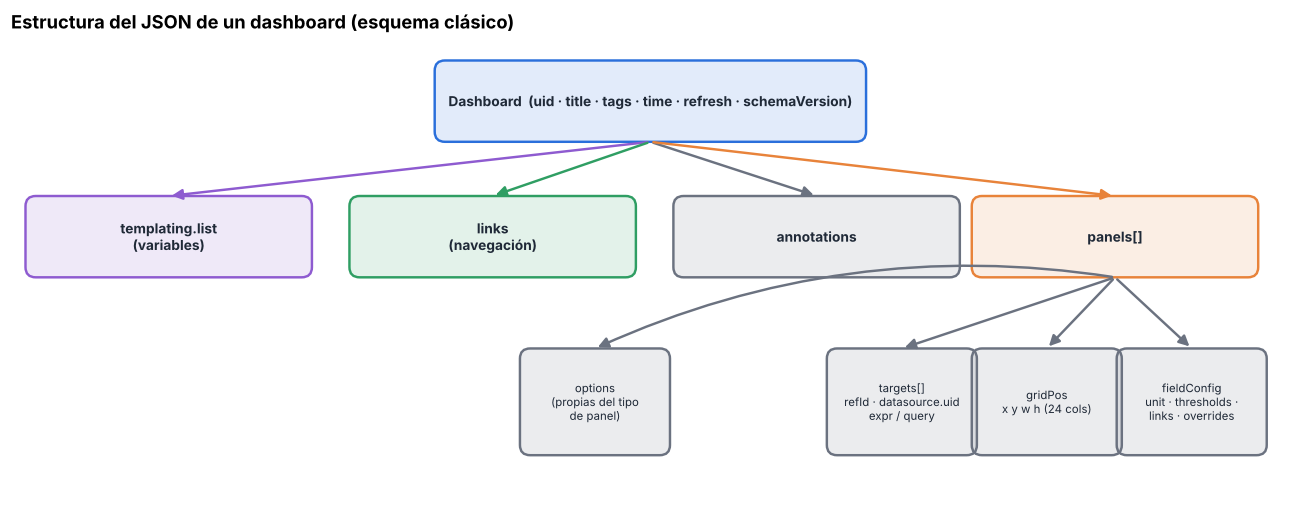

In [5]:
fig, ax = viz.canvas(15, 5.4, xlim=(0, 150), ylim=(0, 54)); P = viz.PALETTE
top = viz.box(ax, 50, 42, 50, 9, "Dashboard  (uid · title · tags · time · refresh · schemaVersion)", P["traces"], bold=True, fontsize=9)
cols = [(2, "templating.list\n(variables)", P["profiles"]), (40, "links\n(navegación)", P["logs"]), (78, "annotations", P["neutral"]), (113, "panels[]", P["metrics"])]
bx = {}
for x, t, c in cols: bx[t] = viz.box(ax, x, 26, 33, 9, t, c, bold=True, fontsize=9); viz.arrow(ax, viz.bottom(top), viz.top(bx[t]), "", c, rad=0)
for x, t in ((96, "targets[]\nrefId · datasource.uid\nexpr / query"), (113, "gridPos\nx y w h (24 cols)"), (130, "fieldConfig\nunit · thresholds ·\nlinks · overrides")):
    b = viz.box(ax, x, 5, 17, 12, t, P["neutral"], fontsize=7.5); viz.arrow(ax, viz.bottom(bx["panels[]"]), viz.top(b), "", P["neutral"], rad=0)
b = viz.box(ax, 60, 5, 17, 12, "options\n(propias del tipo\nde panel)", P["neutral"], fontsize=7.5); viz.arrow(ax, viz.bottom(bx["panels[]"]), viz.top(b), "", P["neutral"], rad=0.15)
ax.set_title("Estructura del JSON de un dashboard (esquema clásico)", loc="left"); plt.show()

## 2.1 Provisioning: del archivo a Grafana

El *provider* de dashboards (`stack/grafana/provisioning/dashboards/dashboards.yaml`) le dice a Grafana **de qué carpeta leer JSON**. Lo leemos del repo:

In [6]:
import yaml
prov = yaml.safe_load((PROV / "dashboards" / "dashboards.yaml").read_text())["providers"][0]
meaning = {"name": "nombre interno del provider", "folder": "carpeta de Grafana donde aparecen", "type": "file = JSON en disco",
           "allowUiUpdates": "True: la UI deja guardar cambios (se almacenan en la BD de Grafana, NO en el archivo)",
           "updateIntervalSeconds": "cada cuántos segundos relee la carpeta", "options": "path = carpeta montada en el contenedor"}
display(pd.DataFrame([{"clave": k, "valor": str(v), "significado": meaning.get(k, "")} for k, v in prov.items()]))
print("Dashboards del repo:", sorted(p.name for p in DASH_DIR.glob("*.json")))

,clave,valor,significado
0,name,course,nombre interno del provider
1,orgId,1,
2,folder,Curso observabilidad de agentes,carpeta de Grafana donde aparecen
3,type,file,file = JSON en disco
4,disableDeletion,False,
5,allowUiUpdates,True,"True: la UI deja guardar cambios (se almacenan en la BD de Grafana, NO en el archivo)"
6,updateIntervalSeconds,10,cada cuántos segundos relee la carpeta
7,options,"{'path': '/var/lib/grafana/dashboards', 'foldersFromFilesStructure': False}",path = carpeta montada en el contenedor


Dashboards del repo: ['00-stack-overview.json', '07-tempo-traceql.json', '08-logs-agente.json', '09-genai-metrics.json', '10-salud-del-agente.json', '11-multiagente.json', '12-mcp-tools.json', '13-finops.json']


> **🧠 Secretos de la élite · Provisioning: el archivo manda… hasta que alguien guarda en la UI**
>
> Con `allowUiUpdates: true` cualquiera puede *guardar* un cambio desde el navegador; queda en la base de datos de Grafana y el archivo **no** cambia. Grafana solo vuelve a aplicar el archivo cuando éste **cambia** (su fecha/versión); hasta entonces, la UI y el repo **divergen en silencio**. Para el laboratorio es cómodo; en producción se pone `allowUiUpdates: false` (los dashboards provisionados son de solo lectura) y se cambia el repo. Lo verificamos en la sección 7.

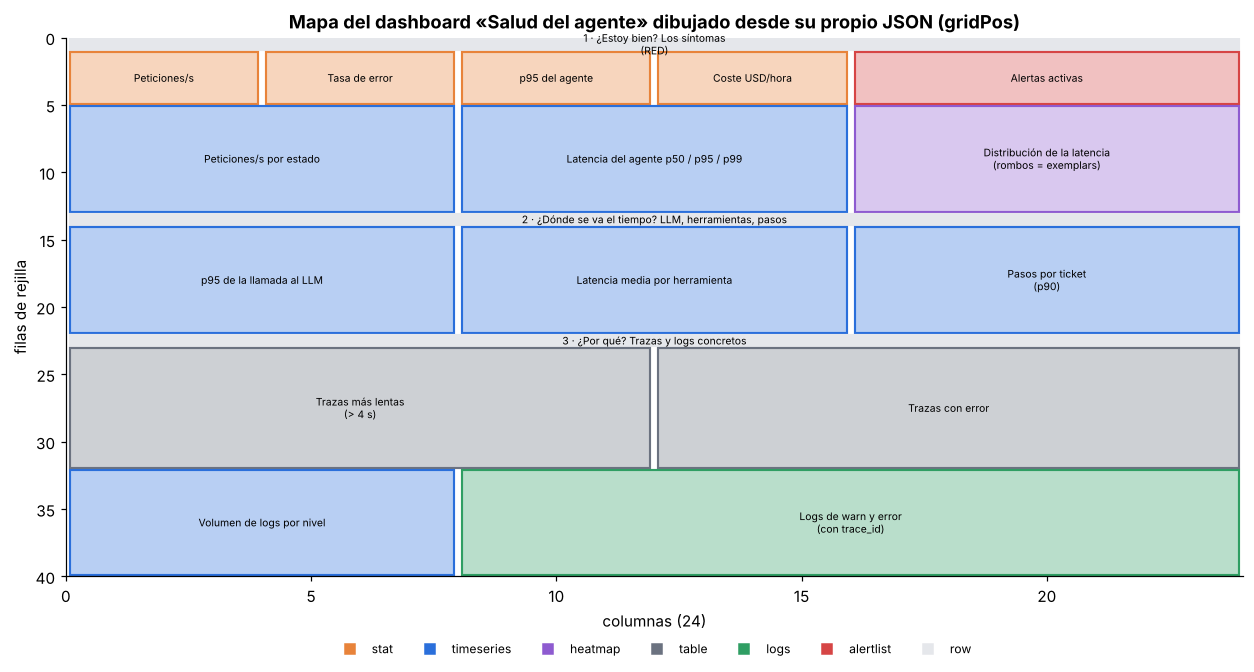

In [7]:
d10 = json.loads((DASH_DIR / "10-salud-del-agente.json").read_text())
fig, ax = plt.subplots(figsize=(11.5, 6.2)); ax.set_xlim(0, 24); ax.set_ylim(0, 1); ax.invert_yaxis()
kinds = {"stat": viz.PALETTE["metrics"], "timeseries": viz.PALETTE["traces"], "heatmap": viz.PALETTE["profiles"], "table": viz.PALETTE["neutral"],
         "logs": viz.PALETTE["logs"], "alertlist": viz.PALETTE["error"], "row": "#e5e7eb"}
ymax = 0
for p in d10["panels"]:
    g = p["gridPos"]; ymax = max(ymax, g["y"] + g["h"]); c = kinds.get(p["type"], "#999")
    ax.add_patch(plt.Rectangle((g["x"] + .08, g["y"] + .08), g["w"] - .16, g["h"] - .16, facecolor=c + "55" if p["type"] != "row" else c, edgecolor=c, lw=1.4))
    ax.text(g["x"] + g["w"] / 2, g["y"] + g["h"] / 2, p["title"].replace(" (", "\n("), ha="center", va="center", fontsize=6.8)
ax.set_ylim(ymax, 0); ax.set_xlabel("columnas (24)"); ax.set_ylabel("filas de rejilla"); ax.grid(False)
for t, c in kinds.items(): ax.plot([], [], "s", color=c, label=t)
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(.5, -.1), fontsize=8); ax.set_title("Mapa del dashboard «Salud del agente» dibujado desde su propio JSON (gridPos)")
plt.tight_layout(); plt.show()

> 👀 **Qué debes observar**
>
> - La rejilla se lee de arriba abajo: **fila 1** (síntomas: 4 *stats* + alertas), **fila 2** (dónde: LLM, herramientas, pasos) y **fila 3** (por qué: trazas y logs). Es la **jerarquía general → específico** que pide la guía de Grafana.
> - Los *stats* son pequeños (4 columnas) y las series ocupan 8: el ojo compara de un vistazo y baja solo si algo está en rojo.
> - Todo esto es **datos** (`gridPos` de cada panel): por eso puede *generarse* y revisarse en un diff.

---
# 3 · Dashboards como código

Exportar un dashboard desde la UI genera **cientos de líneas** (ids, versiones, valores por defecto) que nadie revisa. «Como código» significa generar el JSON desde una descripción corta, **determinista** (misma entrada → mismo JSON) y revisable. Con la librería didáctica `supportops.dashkit` (una versión mínima de lo que hacen Grafonnet o el Foundation SDK):

In [8]:
def mi_dashboard() -> dk.Dashboard:
    d = dk.Dashboard("mi-primero", "TEST: mi primer dashboard como código", tags=["curso", "test"], time_from="now-15m")
    d.variable(dk.var_query("tier", "label_values(supportops_agent_requests_total, supportops_customer_tier)", label="Tier"))
    d.row("Síntomas")
    d.add(dk.stat("Peticiones/s", 'sum(rate(supportops_agent_requests_total{supportops_customer_tier=~"$tier"}[$__rate_interval]))', unit="reqps", decimals=2,
                  description="Tasa de tickets. rate() de un Counter con $__rate_interval."),
          dk.timeseries("p95 del agente", [dk.prom('histogram_quantile(0.95, sum by (le) (rate(gen_ai_invoke_agent_duration_seconds_bucket[$__rate_interval])))', "p95")], unit="s", w=10,
                        description="histogram_quantile sobre sum by (le)."))
    return d

a, b = mi_dashboard().to_json(), mi_dashboard().to_json()
print("determinista:", hashlib.sha256(a.encode()).hexdigest()[:12] == hashlib.sha256(b.encode()).hexdigest()[:12], "· líneas de JSON:", len(a.splitlines()))
print("lint:", dk.lint(mi_dashboard().to_dict()) or "sin problemas")
bad = mi_dashboard().to_dict(); bad["panels"][-1]["description"] = ""; bad["panels"][-1]["targets"][0]["datasource"] = {}; bad.pop("tags")
print("lint de un dashboard descuidado:", dk.lint(bad))

determinista: True · líneas de JSON: 217
lint: sin problemas
lint de un dashboard descuidado: ['sin tags (no se podrá enlazar por tags)', '«p95 del agente»: sin description (qué mide y cómo leerlo)']


**`lint`** comprueba higiene (uid, *tags*, títulos, `description` en cada panel, datasource en cada consulta, ventanas de `rate` razonables). Pero un dashboard puede pasar el *lint* y tener **consultas rotas**. La segunda defensa es **ejecutar cada consulta contra Grafana** (`/api/ds/query`), que es exactamente lo que hace el panel al dibujarse:

In [9]:
if LIVE:
    chk = pd.DataFrame(dk.query_check(mi_dashboard().to_dict()))
    display(chk)
    broken = mi_dashboard().to_dict(); broken["panels"][-1]["targets"][0]["expr"] = "histogram_quantile(0.95, sum by (le) (rate(metrica_que_no_existe_bucket[1m])"   # paréntesis sin cerrar
    print("\nConsulta con PromQL inválido ->", [ (r["ok"], r["error"][:90]) for r in dk.query_check(broken)][-1])
else:
    print("Sin Grafana: query_check() ejecutaría cada consulta con POST /api/ds/query y devolvería ok/frames/rows/error por panel.")

,panel,refId,datasource,ok,frames,rows,error
0,Peticiones/s,A,prometheus,True,1,0,
1,p95 del agente,A,prometheus,True,1,0,



Consulta con PromQL inválido -> (False, '{"results":{"A":{"error":"bad_data: invalid parameter \\"query\\": 1:77: parse error: unclos')


Con esas dos piezas tienes un **control de calidad automatizable en CI**: `lint` en cada *pull request* y `query_check` contra un Grafana efímero. El resto del ecosistema (estado a oct-2026, verificado en los README oficiales):

| Herramienta | Qué es | Estado |
|---|---|---|
| **Grafana Foundation SDK** | Tipos y *builders* **tipados** para definir dashboards y otros recursos en Go, TypeScript, **Python**, PHP y Java; pensado para Grafana ≥ 12 (funciona desde 10) | Vigente |
| **Grafonnet** | Biblioteca de Jsonnet para generar dashboards; **generada** a partir del Foundation SDK | Vigente |
| **grafanalib** | Biblioteca Python para generar dashboards (la cita la guía de buenas prácticas de Grafana) | Comunitaria |
| **Terraform provider de Grafana** | Dashboards, datasources, alertas y más como recursos de Terraform | Vigente |
| **grafanactl** y **Grizzly** | CLIs para gestionar recursos de Grafana desde ficheros | **En desuso**: el README de `grafanactl` anuncia su archivo (1-jun-2026) y su sustitución por **`gcx`** (Grafana 12+); Grizzly estaba marcado para ser sustituido por grafanactl |

Regla práctica: empieza con **JSON provisionado** (esta lección), pasa a un **generador** (dashkit/Foundation SDK/Grafonnet) cuando tengas más de 3 dashboards parecidos, y a **Terraform/gcx** cuando gestiones varias instancias.

---
# 4 · Variables: un dashboard, muchos servicios

Sin variables acabas con un dashboard por servicio, por entorno, por cliente (*sprawl*). Una **variable** es un valor que el usuario elige en la cabecera y que se **interpola** en las consultas (`$tier`, `${service}`).

| Tipo | Para qué | Ejemplo en «Salud del agente» |
|---|---|---|
| **query** | Valores salidos de un datasource | `label_values(supportops_agent_requests_total, supportops_customer_tier)` |
| **custom** | Lista fija | `1m,5m,15m` |
| **interval** | Ventanas de tiempo para agregar | `$agg` |
| **datasource** | Cambiar el backend (mismo dashboard, otro Prometheus) | `$ds` |
| **textbox** | Texto libre | `$search` (filtra líneas de log con `\|= "$search"`) |
| *constant / ad hoc* | Valores fijos / filtros libres | — |

Detalles que muerden: con **multi-valor** y **«All»**, Grafana expande la variable a una regex (`a|b|c`, o `.*` si defines `allValue`), así que en PromQL/LogQL hay que usar **`=~`** (no `=`); y una variable *query* se **refresca** al cargar (`refresh: 1`) o al cambiar el rango de tiempo (`refresh: 2`): esta última cuesta una consulta extra por cambio.

## `$__rate_interval`: la ventana correcta para `rate()`

En el módulo 09 viste que `rate(x[15s])` con *scrape* de 15 s devuelve vacío. Grafana resuelve el problema con la variable **`$__rate_interval`**:

$$\text{\$\_\_rate\_interval}=\max\big(\,\text{\$\_\_interval}+\text{scrape},\ 4\times\text{scrape}\,\big)$$

donde `$__interval` es el paso de la gráfica (rango ÷ puntos que caben en el panel) y *scrape* es el **intervalo de scrape configurado en el datasource** (`timeInterval: 15s` en `datasources.yaml`). Garantiza **≥ 4 muestras** por ventana pase lo que pase. Lo calculamos y lo verificamos contra Grafana:

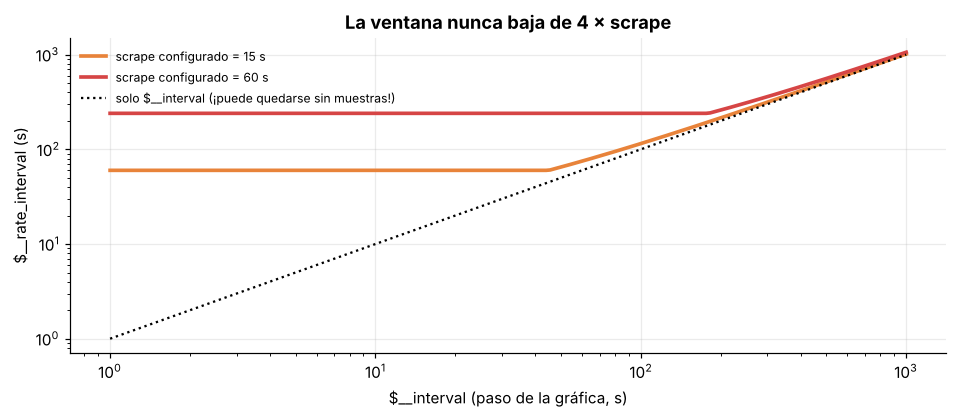

{'$__interval=5s': '60s', '$__interval=15s': '60s', '$__interval=60s': '75s', '$__interval=300s': '315s'}


In [10]:
def rate_interval(interval_s: float, scrape_s: float = 15) -> float:
    return max(interval_s + scrape_s, 4 * scrape_s)

iv = np.logspace(0, 3, 200)
fig, ax = plt.subplots(figsize=(8.8, 3.9))
for sc, c in ((15, viz.PALETTE["metrics"]), (60, viz.PALETTE["error"])):
    ax.plot(iv, [rate_interval(i, sc) for i in iv], color=c, lw=2.4, label=f"scrape configurado = {sc} s")
ax.plot(iv, iv, "k:", label="solo $__interval (¡puede quedarse sin muestras!)"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("$__interval (paso de la gráfica, s)"); ax.set_ylabel("$__rate_interval (s)"); ax.set_title("La ventana nunca baja de 4 × scrape"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print({f"$__interval={i}s": f"{rate_interval(i):.0f}s" for i in (5, 15, 60, 300)})

In [11]:
def ds_query(queries: list[dict], minutes: int = 15, interval_ms: int = 30000) -> dict:
    """POST /api/ds/query: lo mismo que hace un panel al dibujarse. Cada query lleva refId y datasource."""
    qs = [{"intervalMs": interval_ms, "maxDataPoints": 300, **q} for q in queries]
    return dk.grafana("POST", "/api/ds/query", {"queries": qs, "from": f"now-{minutes}m", "to": "now"})

if LIVE:
    rows = []
    for ims in (1000, 15000, 60000, 300000):
        res = ds_query([{"refId": "A", "datasource": dk.DS_PROM, "expr": "sum(rate(supportops_agent_requests_total[$__rate_interval]))", "range": True}], interval_ms=ims)
        meta = ((res["results"]["A"]["frames"] or [{}])[0].get("schema", {}).get("meta", {}))
        ex = meta.get("executedQueryString", "")
        rows.append({"$__interval (ms)": ims, "ventana que resolvió Grafana": (re.findall(r"\[(\w+)\]", ex) or ["?"])[0], "calculada a mano": f"{rate_interval(ims / 1000):.0f}s"})
    display(pd.DataFrame(rows))
    tiers = dk.grafana("GET", "/api/datasources/proxy/uid/prometheus/api/v1/label/supportops_customer_tier/values")
    print("valores de la variable $tier (label_values):", tiers.get("data") or "(aún sin datos: se llenará con el tráfico de la sección 5)")
else:
    print("Sin Grafana: la ventana la resuelve Grafana al ejecutar la consulta (aquí la calculamos a mano).")

,$__interval (ms),ventana que resolvió Grafana,calculada a mano
0,1000,1m0s,60s
1,15000,1m0s,60s
2,60000,1m15s,75s
3,300000,5m15s,315s


valores de la variable $tier (label_values): (aún sin datos: se llenará con el tráfico de la sección 5)


> 👀 **Qué debes observar**
>
> - La curva naranja nunca baja de 60 s (4 × 15 s): **aunque amplíes el zoom** hasta pasos de 1 s, `rate()` mira ≥ 4 muestras. La roja (scrape de 60 s) sube a 240 s.
> - La tabla compara lo que **Grafana resolvió** con nuestra fórmula: coinciden. Fíjate también en que con pasos grandes la ventana crece (`$__interval + scrape`).
> - **Trampa:** si el `timeInterval` del datasource dice 15 s pero Prometheus raspa cada 60 s, `$__rate_interval` = 60 s y `rate()` solo tiene 1 muestra: **panel vacío**. El ajuste del datasource debe reflejar la realidad (no se puede deducir: Prometheus no guarda históricos del intervalo).

---
# 5 · Paneles para cada señal

Elige la visualización según la **pregunta**:

| Señal | Pregunta | Panel | Consulta (ejemplo) |
|---|---|---|---|
| Métrica | ¿Cuál es el valor ahora, bueno o malo? | **stat** (con umbrales) | `sum(rate(...[$__rate_interval]))` |
| Métrica | ¿Cómo evoluciona? ¿Hay picos? | **time series** | `histogram_quantile(0.95, sum by (le)(rate(..._bucket[...])))` |
| Métrica | ¿Cómo se **distribuye** la latencia? (y rombos de exemplars) | **heatmap** | `sum by (le)(rate(..._bucket[...]))` con *format heatmap* y `exemplar: true` |
| Traza | ¿Cuáles son las peores peticiones? | **table** (TraceQL, `tableType: traces`) | `{ resource.service.name = "x" && duration > 4s }` |
| Log | ¿Qué dijeron los logs? | **logs** | `{service_name="x", detected_level=~"warn\|error"}` |
| Log | ¿Cuánto log y de qué nivel? | **time series** (LogQL de métrica) | `sum by (detected_level)(count_over_time({...}[$__interval]))` |

Para tener datos reales, enviamos **tráfico en vivo con las tres señales** (trazas, métricas y logs) con un incidente en el último tercio: *proveedor lento* y una ráfaga de **errores 503** (suficiente para disparar la alerta de la sección 8). En segundo plano **sondeamos el estado de las alertas** para dibujar su ciclo de vida después.

In [12]:
import threading
SECS = 110 if FAST_DEV_RUN else 240
INCIDENTS = [Incident("llm_lento", "latency_spike", SECS * 0.50, SECS * 0.85, 0.75, {"factor": 5.0, "target": "llm"}),
             Incident("proveedor_caido", "llm_error", SECS * 0.55, SECS * 0.85, 0.9, {"status": 503, "persistent": True})]
ALERT_STATES: list[tuple[float, str, str]] = []          # (t, uid de la regla, estado)

def poll_alerts(stop: threading.Event, every: float = 5.0):
    while not stop.is_set():
        try:
            for g in dk.grafana("GET", "/api/prometheus/grafana/api/v1/rules")["data"]["groups"]:
                for r in g["rules"]:
                    ALERT_STATES.append((time.time(), r.get("uid") or r["name"], r["state"]))
        except Exception:
            pass
        stop.wait(every)

if LIVE:
    TEL = setup_telemetry("supportops-agent", metric_interval_s=5)
    AGENT = SupportAgent(instrumentor=CompositeInstrumentor(OTelInstrumentor(TEL, emit_metrics=False), MetricsInstrumentor(TEL)))
    TK = generate_tickets(SECS * 2, seed=SEED, duration_s=SECS, fault_rates=DEFAULT_FAULT_RATES, incidents=INCIDENTS, start_s=0.0)
    stop = threading.Event(); th = threading.Thread(target=poll_alerts, args=(stop,), daemon=True); th.start()
    T0 = time.time(); RES = run_live(AGENT, TK, SECS, progress_every=40); T1 = time.time()
    TEL.force_flush(); print(f"{len(RES)} tickets en {T1 - T0:.0f} s · esperando a Prometheus/Loki/Tempo…"); time.sleep(25)
    RUNS = pd.DataFrame(to_rows(TK, RES)); print(RUNS.status.value_counts().to_dict())
else:
    print("Sin stack: se omite el tráfico en vivo.")

  … 70/220 tickets (40s)


Transient error HTTPConnectionPool(host='localhost', port=4318): Max retries exceeded with url: /v1/traces (Caused by NewConnectionError("HTTPConnection(host='localhost', port=4318): Failed to establish a new connection: [Errno 111] Connection refused")) encountered while exporting spans batch, retrying in 0.95s.


Transient error HTTPConnectionPool(host='localhost', port=4318): Max retries exceeded with url: /v1/logs (Caused by NewConnectionError("HTTPConnection(host='localhost', port=4318): Failed to establish a new connection: [Errno 111] Connection refused")) encountered while exporting logs batch, retrying in 0.96s.


Transient error HTTPConnectionPool(host='localhost', port=4318): Max retries exceeded with url: /v1/traces (Caused by NewConnectionError("HTTPConnection(host='localhost', port=4318): Failed to establish a new connection: [Errno 111] Connection refused")) encountered while exporting spans batch, retrying in 2.28s.


Transient error HTTPConnectionPool(host='localhost', port=4318): Max retries exceeded with url: /v1/metrics (Caused by NewConnectionError("HTTPConnection(host='localhost', port=4318): Failed to establish a new connection: [Errno 111] Connection refused")) encountered while exporting metrics batch, retrying in 1.19s.


...

Transient error HTTPConnectionPool(host='localhost', port=4318): Max retries exceeded with url: /v1/metrics (Caused by NewConnectionError("HTTPConnection(host='localhost', port=4318): Failed to establish a new connection: [Errno 111] Connection refused")) encountered while exporting metrics batch, retrying in 2.00s.


Failed to export spans batch due to timeout, max retries or shutdown.


  … 175/220 tickets (81s)


220 tickets en 110 s · esperando a Prometheus/Loki/Tempo…


{'ok': 125, 'error': 71, 'escalated': 20, 'degraded': 3, 'max_steps': 1}


In [13]:
def frames_df(res: dict, ref: str = "A") -> pd.DataFrame:
    """Respuesta de /api/ds/query -> DataFrame (una columna por campo; `serie` identifica cada frame)."""
    out = []
    for i, fr in enumerate(res["results"][ref].get("frames", [])):
        names = [f["name"] for f in fr["schema"]["fields"]]; df = pd.DataFrame(dict(zip(names, fr["data"]["values"])))
        lab = next((f.get("labels") for f in fr["schema"]["fields"] if f.get("labels")), {}) or {}
        out.append(df.assign(serie=",".join(f"{k}={v}" for k, v in lab.items()) or fr["schema"].get("name", str(i))))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

if LIVE:
    mins = int((time.time() - T0) / 60) + 2
    P95 = frames_df(ds_query([{"refId": "A", "datasource": dk.DS_PROM, "range": True, "expr": 'histogram_quantile(0.95, sum by (le) (rate(gen_ai_invoke_agent_duration_seconds_bucket{service_name="supportops-agent"}[$__rate_interval])))'}], mins))
    LOGV = frames_df(ds_query([{"refId": "A", "datasource": dk.DS_LOKI, "queryType": "range", "expr": 'sum by (detected_level) (count_over_time({service_name="supportops-agent"}[$__interval]))'}], mins))
    TR = frames_df(ds_query([{"refId": "A", "datasource": dk.DS_TEMPO, "queryType": "traceql", "tableType": "traces", "limit": 15,
                              "query": '{ resource.service.name = "supportops-agent" && name =~ "invoke_agent.*" && duration > 4s }'}], mins))
    print("PromQL ->", P95.shape, "| LogQL ->", LOGV.shape, "| TraceQL ->", TR.shape, "· columnas de la tabla de trazas:", list(TR.columns))

PromQL -> (2, 3) | LogQL -> (18, 3) | TraceQL -> (11, 7) · columnas de la tabla de trazas: ['traceID', 'startTime', 'traceService', 'traceName', 'traceDuration', 'nested', 'serie']


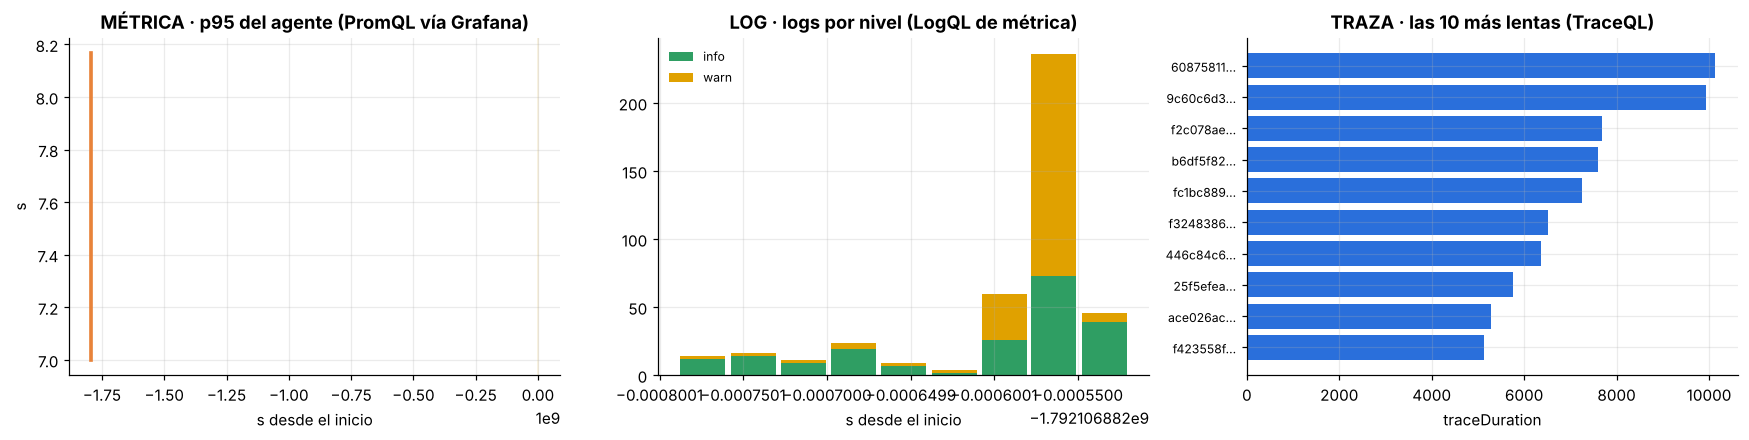

In [14]:
if LIVE:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.1))
    if len(P95):
        axes[0].plot((pd.to_datetime(P95.iloc[:, 0], unit="ms").astype("int64") / 1e9) - T0, P95.iloc[:, 1], color=viz.PALETTE["metrics"], lw=2.4)
    for a, b in ((SECS * 0.5, SECS * 0.85),): axes[0].axvspan(a, b, color=viz.PALETTE["warn"], alpha=.15)
    axes[0].set_title("MÉTRICA · p95 del agente (PromQL vía Grafana)"); axes[0].set_xlabel("s desde el inicio"); axes[0].set_ylabel("s")
    if len(LOGV):
        pv = LOGV.pivot_table(index=LOGV.columns[0], columns="serie", values=LOGV.columns[1], aggfunc="sum").fillna(0)
        t = (pd.to_datetime(pv.index, unit="ms").astype("int64") / 1e9) - T0
        bottom = np.zeros(len(pv)); colr = {"info": viz.PALETTE["logs"], "warn": viz.PALETTE["warn"], "error": viz.PALETTE["error"]}
        for c in pv.columns:
            axes[1].bar(t, pv[c].values, bottom=bottom, width=(float(np.median(np.diff(t.values))) if len(t) > 1 else 5) * .9, color=colr.get(c.split("=")[-1], "#999"), label=c.split("=")[-1]); bottom += pv[c].values
        axes[1].legend(fontsize=8)
    axes[1].set_title("LOG · logs por nivel (LogQL de métrica)"); axes[1].set_xlabel("s desde el inicio")
    if len(TR):
        dcol = next(c for c in TR.columns if "uration" in c); top = TR.sort_values(dcol, ascending=False).head(10)
        axes[2].barh(range(len(top)), top[dcol], color=viz.PALETTE["traces"]); axes[2].set_yticks(range(len(top))); axes[2].set_yticklabels([str(x)[:8] + "…" for x in top.traceID], fontsize=8)
        axes[2].invert_yaxis(); axes[2].set_xlabel(dcol)
    axes[2].set_title("TRAZA · las 10 más lentas (TraceQL)")
    plt.tight_layout(); plt.show()

> 👀 **Qué debes observar**
>
> - **Tres lenguajes, una misma API:** `POST /api/ds/query` devuelve *frames* tanto para PromQL como para LogQL y TraceQL. Un panel de Grafana no es más que esto + una forma de dibujarlo.
> - En la métrica, la franja amarilla (incidente) eleva el p95; en los logs, aparecen **WARN/ERROR** que antes casi no había; en las trazas, las más lentas son de la franja del incidente. **Las tres señales cuentan la misma historia desde ángulos distintos.**
> - La tabla de trazas trae el **`traceID`**: es el hilo para saltar a la traza y de ahí a sus logs.

![Dashboard «Salud del agente» durante el incidente: fila de síntomas con la tasa de error y el p95 en naranja/rojo, alertas activas, series, mapa de calor con exemplars, latencias por LLM y herramienta, tablas de trazas y logs](img/10_salud_incidente.png)

*Captura real del dashboard `10-salud-del-agente.json` (Grafana 13.2.4) tomada justo tras el incidente de esta sección.* **Qué debe ver el alumno:** (1) arriba, *Tasa de error* y *p95 del agente* **en color** (naranja/rojo) y el panel *Alertas activas* con la regla de error en *Firing*/*Pending*; (2) en el centro, el mapa de calor con cuadrados magenta (exemplars) más calientes en los buckets de 5-10 s; (3) en la fila 2, el p95 de la llamada al LLM disparado y `escalate_to_human`/`issue_refund` como herramientas más lentas; (4) abajo, la tabla de **trazas más lentas** (traceID con enlace), la de trazas con error, el volumen de logs por nivel y los logs de warn/error. Todo cambia con las variables de la cabecera (`Servicio`, `Tier`, `Buscar en logs`).

---
# 6 · Correlación: de una señal a la siguiente

El valor de tener tres señales está en **saltar** entre ellas sin perder el contexto. Hay cuatro mecanismos, todos ya configurados en el stack del curso (`datasources.yaml`) salvo los *data links*, que van en el dashboard:

| Salto | Mecanismo | Dónde se configura |
|---|---|---|
| métrica → traza | **Exemplar** (`trace_id`) | datasource Prometheus: `exemplarTraceIdDestinations`; consulta con `exemplar: true` |
| traza → logs | **`tracesToLogsV2`** (consulta con `trace_id`) | datasource Tempo |
| traza → métricas | **`tracesToMetrics`** | datasource Tempo |
| log → traza | **Derived field** `trace_id` | datasource Loki |
| panel → Explore (cualquier señal) | **Data link** con la consulta y el rango de tiempo ya rellenados | `fieldConfig.defaults.links` en el panel |
| dashboard → dashboard | **Dashboard links** (`keepTime`, `includeVars`) | `links` del dashboard |

In [15]:
if LIVE:
    cfg = {u: dk.grafana("GET", f"/api/datasources/uid/{u}")["jsonData"] for u in ("tempo", "loki", "prometheus")}
    show = pd.DataFrame([
        {"datasource": "Prometheus", "campo": "exemplarTraceIdDestinations", "valor": json.dumps(cfg["prometheus"].get("exemplarTraceIdDestinations"))},
        {"datasource": "Tempo", "campo": "tracesToLogsV2", "valor": json.dumps({k: cfg["tempo"]["tracesToLogsV2"][k] for k in ("datasourceUid", "filterByTraceID", "query")})},
        {"datasource": "Tempo", "campo": "tracesToMetrics", "valor": json.dumps({"datasourceUid": cfg["tempo"]["tracesToMetrics"]["datasourceUid"]})},
        {"datasource": "Loki", "campo": "derivedFields", "valor": json.dumps([{k: f[k] for k in ("name", "matcherRegex", "datasourceUid")} for f in cfg["loki"]["derivedFields"]])},
        {"datasource": "Prometheus", "campo": "timeInterval (scrape)", "valor": cfg["prometheus"].get("timeInterval")}])
    display(show)
else:
    print("Sin Grafana: estos campos están en stack/grafana/provisioning/datasources/datasources.yaml")

,datasource,campo,valor
0,Prometheus,exemplarTraceIdDestinations,"[{""datasourceUid"": ""tempo"", ""name"": ""trace_id""}]"
1,Tempo,tracesToLogsV2,"{""datasourceUid"": ""loki"", ""filterByTraceID"": true, ""query"": ""{service_name=\""${__span.tags[\""ser..."
2,Tempo,tracesToMetrics,"{""datasourceUid"": ""prometheus""}"
3,Loki,derivedFields,"[{""name"": ""trace_id"", ""matcherRegex"": ""trace_id"", ""datasourceUid"": ""tempo""}]"
4,Prometheus,timeInterval (scrape),15s


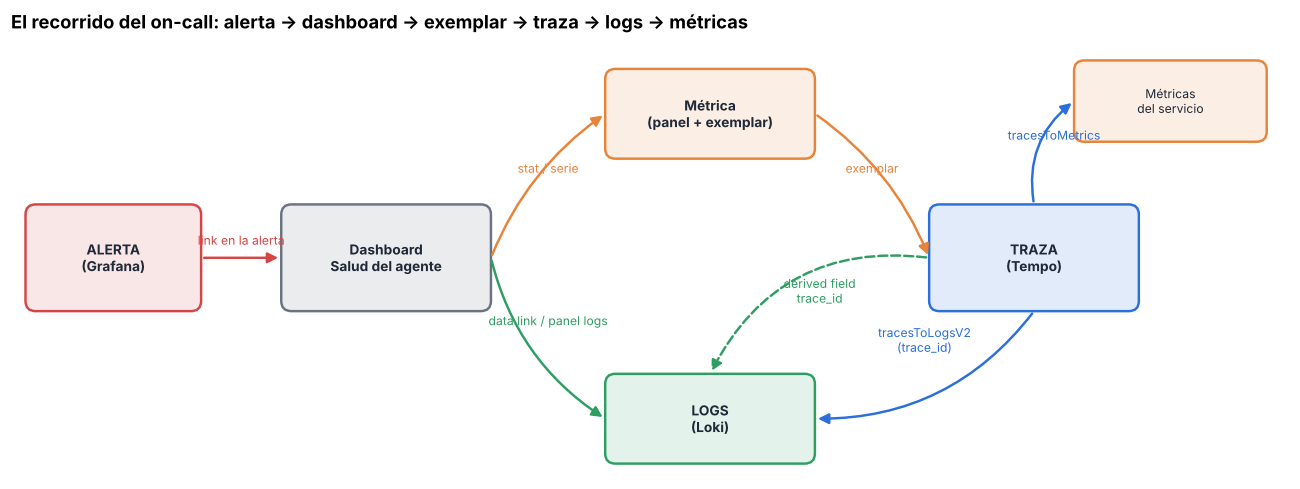

In [16]:
fig, ax = viz.canvas(15, 5.2, xlim=(0, 150), ylim=(0, 52)); P = viz.PALETTE
al = viz.box(ax, 2, 20, 20, 12, "ALERTA\n(Grafana)", P["error"], bold=True)
db = viz.box(ax, 32, 20, 24, 12, "Dashboard\nSalud del agente", P["neutral"], bold=True)
mt = viz.box(ax, 70, 38, 24, 10, "Métrica\n(panel + exemplar)", P["metrics"], bold=True)
tr = viz.box(ax, 108, 20, 24, 12, "TRAZA\n(Tempo)", P["traces"], bold=True)
lg = viz.box(ax, 70, 2, 24, 10, "LOGS\n(Loki)", P["logs"], bold=True)
mm = viz.box(ax, 125, 40, 22, 9, "Métricas\ndel servicio", P["metrics"], fontsize=8)
viz.arrow(ax, viz.right(al), viz.left(db), "link en la alerta", P["error"])
viz.arrow(ax, viz.right(db), viz.left(mt), "stat / serie", P["metrics"], rad=-0.15)
viz.arrow(ax, viz.right(mt), viz.left(tr), "exemplar", P["metrics"], rad=-0.15)
viz.arrow(ax, viz.right(db), viz.left(lg), "data link / panel logs", P["logs"], rad=0.2)
viz.arrow(ax, viz.top(tr), viz.left(mm), "tracesToMetrics", P["traces"], rad=-0.3)
viz.arrow(ax, viz.bottom(tr), viz.right(lg), "tracesToLogsV2\n(trace_id)", P["traces"], rad=-0.25)
viz.arrow(ax, viz.left(tr), viz.top(lg), "derived field\ntrace_id", P["logs"], rad=0.35, dashed=True)
ax.set_title("El recorrido del on-call: alerta → dashboard → exemplar → traza → logs → métricas", loc="left"); plt.show()

> 👀 **Qué debes observar**
>
> - Cada flecha es **un enlace configurado como código**, no magia. Si falta uno (p. ej. `trace_id` no llega a Loki), el recorrido se **rompe** en ese punto: por eso conviene *recorrerlo con un ticket real* tras cada cambio de instrumentación.
> - El camino típico a las 3 de la mañana: la alerta lleva al dashboard (`dashboardUid` + `panelId`), el *stat* en rojo lleva a la métrica, el exemplar a **la** traza lenta, la traza a **sus** logs. Cuatro clics, sin escribir una consulta.

## 6.1 Recorrer el camino «a mano» (por API)

Hacemos programáticamente lo que haría un clic: **exemplar más lento → traza → logs de esa traza → métricas en ese instante**, y comprobamos que cada salto devuelve algo.

In [17]:
def walk(trace_id: str) -> dict:
    sp = tempo_spans(backends.tempo_trace(trace_id))
    t_start = min(s["start_unix_nano"] for s in sp) / 1e9
    logs = backends.loki_query(f'{{service_name="supportops-agent"}} | trace_id="{trace_id}"', minutes=30, limit=50)
    rate = prom_instant('sum(rate(supportops_agent_requests_total{service_name="supportops-agent"}[1m]))', at=time.time())
    return {"spans": len(sp), "nombres": sorted({s["name"].split()[0] for s in sp}), "logs": len(logs), "mensajes": sorted({l["line"][:45] for l in logs})[:3],
            "req/s ahora": round(rate[0]["value"], 2) if rate else None}

if LIVE:
    ex = [e for e in prom_exemplars("gen_ai_invoke_agent_duration_seconds_bucket", minutes=int((time.time() - T0) / 60) + 2) if e["series"].get("service_name") == "supportops-agent"]
    ex.sort(key=lambda e: -e["value"]); trace_id = ex[0]["trace_id"]
    hop = {"1 · métrica → exemplar": f"{len(ex)} exemplars; el mayor: {ex[0]['value']:.1f} s", "2 · exemplar → traza (Tempo)": None, "3 · traza → logs (Loki)": None, "4 · → métricas (Prometheus)": None}
    for _ in range(10):                                                       # Tempo/Loki tardan unos segundos en indexar
        try:
            w = walk(trace_id)
            if w["spans"] and w["logs"]: break
        except Exception: w = {"spans": 0, "logs": 0}
        time.sleep(4)
    hop["2 · exemplar → traza (Tempo)"] = f"{w['spans']} spans: {w.get('nombres')}"; hop["3 · traza → logs (Loki)"] = f"{w['logs']} logs: {w.get('mensajes')}"; hop["4 · → métricas (Prometheus)"] = f"{w.get('req/s ahora')} req/s ahora"
    display(pd.DataFrame({"salto": list(hop), "resultado": list(hop.values())}).set_index("salto")); print("trace_id:", trace_id)
else:
    print("Sin stack: el recorrido es exemplar -> Tempo /api/traces/<id> -> Loki | trace_id=\"<id>\" -> Prometheus.")

,resultado
salto,
1 · métrica → exemplar,14 exemplars; el mayor: 7.7 s
2 · exemplar → traza (Tempo),"4 spans: ['chat', 'execute_tool', 'invoke_agent']"
3 · traza → logs (Loki),"2 logs: ['ticket recibido', 'ticket resuelto']"
4 · → métricas (Prometheus),0.69 req/s ahora


trace_id: f2c078ae0fd00fac239178367a0ce7bc


## 6.2 Data links y correlaciones **como código**

Un *data link* es una URL con variables: Grafana sustituye `${__from}`, `${__to}` (rango del panel), `${__value.raw}` (valor de la celda), `${__field.labels.x}` (etiqueta de la serie) y las variables del dashboard. `dk.explore_url()` construye la URL de **Explore** con la consulta ya escrita. Así, un clic en el *stat* de p95 abre las **trazas lentas de ese mismo intervalo**:

In [18]:
slow = [p for p in d10["panels"] if p.get("title") == "p95 del agente"][0]
lk = slow["fieldConfig"]["defaults"]["links"][0]
print("title:", lk["title"]); print("url  :", lk["url"][:200] + "…")
print("\nvariables que Grafana sustituirá al hacer clic:", sorted(set(re.findall(r"\$\{?(__\w+|service|tier)", lk["url"]))))
print("dashboard links:", [(l["title"], l.get("type"), l.get("tags") or l.get("url")) for l in d10["links"]])

title: Ver trazas lentas (> 4 s)
url  : /explore?schemaVersion=1&panes={"a":{"datasource":"tempo","queries":[{"refId":"A","datasource":{"uid":"tempo"},"queryType":"traceql","query":"{ resource.service.name = \"$service\" && name =~ \"invoke…

variables que Grafana sustituirá al hacer clic: ['__from', '__to', 'service']
dashboard links: [('Métricas GenAI (módulo 09)', 'dashboards', ['metricas']), ('Explore', 'link', '/explore')]


In [19]:
# Correlaciones de Grafana (API): «desde un log, ver las métricas del servicio». Se crean con la API y se pueden provisionar en el YAML del datasource.
if LIVE:
    body = {"targetUID": "prometheus", "label": "Tasa de peticiones del servicio", "description": "De un log al tráfico del mismo servicio", "type": "query",
            "config": {"type": "query", "field": "service_name", "target": {"expr": 'sum(rate(supportops_agent_requests_total{service_name="${service_name}"}[$__rate_interval]))'}}}
    try:
        cr = dk.grafana("POST", "/api/datasources/uid/loki/correlations", body)
        uid = cr.get("result", {}).get("uid") or cr.get("uid")
        lst = dk.grafana("GET", "/api/datasources/uid/loki/correlations")
        print("correlación creada:", uid, "·", [c["label"] for c in (lst if isinstance(lst, list) else lst.get("correlations", []))])
        dk.grafana("DELETE", f"/api/datasources/uid/loki/correlations/{uid}"); print("(borrada para no dejar estado en el laboratorio)")
    except RuntimeError as e:
        print("La API de correlaciones respondió:", str(e)[:200])
else:
    print("Sin Grafana: POST /api/datasources/uid/<origen>/correlations con targetUID, label y config.{type, field, target}.")

correlación creada: cg1clqj5vt4owf · ['Tasa de peticiones del servicio']
(borrada para no dejar estado en el laboratorio)


![Vista Explore de Grafana con la traza lenta abierta desde el enlace de datos: cascada de spans invoke_agent, chat y execute_tool, con el panel de logs relacionados](img/10_explore_traza.png)

*Captura real de **Explore** (Tempo) con la traza abierta a partir de un `traceID` de la tabla.* En la vista de traza, el botón **«Logs for this span»** (datasource Tempo → `tracesToLogsV2`) lanza la consulta `{service_name="supportops-agent"} | trace_id="…"` en Loki con el rango de la traza.

**Explore** es el *banco de pruebas*: allí afinas la consulta (PromQL, LogQL, TraceQL) con sugerencias y *query history*; cuando la tienes, la conviertes en un panel (*Add to dashboard*) **y la llevas al repositorio**. Regla: lo que descubres en Explore y vale la pena repetir, se mete en el JSON.

---
# 7 · El dashboard «Salud del agente»

Diseñado con la lógica **general → específico** (una fila por pregunta) y con navegación a las otras señales:

| Fila | Pregunta | Paneles | Salta a… |
|---|---|---|---|
| 1 · Síntomas | **¿Estoy bien?** | Peticiones/s, **Tasa de error**, **p95**, coste/h, alertas activas; tasa por estado; percentiles; mapa de calor | *stat* de error → logs warn/error · *stat*/serie p95 → trazas lentas · rombos → traza |
| 2 · Dónde | **¿Dónde se va el tiempo?** | p95 del LLM, latencia media por herramienta, pasos p90 | herramienta → trazas de esa herramienta |
| 3 · Por qué | **¿Qué petición concreta?** | Tabla de trazas lentas, tabla de trazas con error, volumen de logs, logs warn/error | `traceID` → Explore (traza) → logs de la traza |

Lo cargamos desde el repo, lo pasamos por las dos validaciones y comprobamos que Grafana lo ha aprovisionado:

In [20]:
rows = []
cur = ""
for p in d10["panels"]:
    if p["type"] == "row": cur = p["title"]; continue
    fc = p.get("fieldConfig", {"defaults": {}, "overrides": []})
    links = len(p.get("links", [])) + len(fc["defaults"].get("links", [])) + sum(len(o["properties"][0]["value"]) for o in fc.get("overrides", []) if o["properties"][0]["id"] == "links")
    rows.append({"fila": cur[:22], "panel": p["title"], "tipo": p["type"], "señal": (p.get("datasource") or {}).get("type", "—"), "enlaces": links})
PANELS = pd.DataFrame(rows); display(PANELS)
print("lint:", dk.lint(d10) or "sin problemas", "· variables:", [(v["name"], v["type"]) for v in d10["templating"]["list"]])
if LIVE:
    chk = pd.DataFrame(dk.query_check(d10, overrides={"service": "supportops-agent"})); chk["consulta OK"] = chk.ok.map({True: "✅", False: "❌"})
    print(f"\nquery_check: {int(chk.ok.sum())}/{len(chk)} consultas correctas · con datos: {int((chk.rows > 0).sum())}")
    display(chk[~chk.ok][["panel", "refId", "error"]] if (~chk.ok).any() else chk[["panel", "datasource", "frames", "rows", "consulta OK"]].head(8))
    g = dk.grafana("GET", "/api/dashboards/uid/salud-agente")
    print("Grafana lo tiene cargado:", g["dashboard"]["title"], "· carpeta:", g["meta"]["folderTitle"], "· version:", g["dashboard"]["version"], "· provisioned:", g["meta"].get("provisioned"))

,fila,panel,tipo,señal,enlaces
0,1 · ¿Estoy bien? Los s,Peticiones/s,stat,prometheus,0
1,1 · ¿Estoy bien? Los s,Tasa de error,stat,prometheus,1
2,1 · ¿Estoy bien? Los s,p95 del agente,stat,prometheus,1
3,1 · ¿Estoy bien? Los s,Coste USD/hora,stat,prometheus,0
4,1 · ¿Estoy bien? Los s,Alertas activas,alertlist,—,0
5,1 · ¿Estoy bien? Los s,Peticiones/s por estado,timeseries,prometheus,0
6,1 · ¿Estoy bien? Los s,Latencia del agente p50 / p95 / p99,timeseries,prometheus,1
7,1 · ¿Estoy bien? Los s,Distribución de la latencia (rombos = exemplars),heatmap,prometheus,0
8,2 · ¿Dónde se va el ti,p95 de la llamada al LLM,timeseries,prometheus,0
9,2 · ¿Dónde se va el ti,Latencia media por herramienta,timeseries,prometheus,1


lint: sin problemas · variables: [('service', 'query'), ('tier', 'query'), ('search', 'textbox')]



query_check: 17/17 consultas correctas · con datos: 15


,panel,datasource,frames,rows,consulta OK
0,Peticiones/s,prometheus,1,2,✅
1,Tasa de error,prometheus,1,2,✅
2,p95 del agente,prometheus,1,2,✅
3,Coste USD/hora,prometheus,1,2,✅
4,Peticiones/s por estado,prometheus,5,10,✅
5,Latencia del agente p50 / p95 / p99,prometheus,1,2,✅
6,Latencia del agente p50 / p95 / p99,prometheus,1,2,✅
7,Latencia del agente p50 / p95 / p99,prometheus,1,2,✅


Grafana lo tiene cargado: 10 · Salud del agente (SupportOps) · carpeta: Curso observabilidad de agentes · version: 1 · provisioned: False


### ¿Qué pasa si alguien «arregla» el dashboard desde la UI?

Probamos lo que advertimos en la sección 2: guardamos un cambio por la API (equivale a pulsar *Save* en la UI) y comparamos con el archivo.

In [21]:
if LIVE:
    orig = json.loads((DASH_DIR / "10-salud-del-agente.json").read_text())
    edited = copy.deepcopy(orig); edited["title"] = orig["title"] + "  (EDITADO EN LA UI)"
    try:
        dk.upload(edited)
        in_grafana = dk.grafana("GET", "/api/dashboards/uid/salud-agente")["dashboard"]["title"]
        print("título en Grafana :", in_grafana); print("título en el ARCHIVO:", json.loads((DASH_DIR / "10-salud-del-agente.json").read_text())["title"])
        print("→ divergen:", in_grafana != orig["title"], "(el repo ya no es la fuente de verdad hasta que alguien lo reconcilie)")
    except RuntimeError as e:
        print("Grafana rechazó el guardado:", str(e)[:200])
    finally:
        dk.upload(orig); print("restaurado desde el archivo:", dk.grafana("GET", "/api/dashboards/uid/salud-agente")["dashboard"]["title"])
else:
    print("Sin Grafana: con allowUiUpdates=true el guardado por UI/API se acepta y diverge del archivo; con false, Grafana lo rechaza.")

título en Grafana : 10 · Salud del agente (SupportOps)  (EDITADO EN LA UI)
título en el ARCHIVO: 10 · Salud del agente (SupportOps)
→ divergen: True (el repo ya no es la fuente de verdad hasta que alguien lo reconcilie)


restaurado desde el archivo: 10 · Salud del agente (SupportOps)


---
# 8 · Alertas básicas, aprovisionadas como código

Una **alerta de Grafana** es una consulta que se evalúa **en el servidor** cada cierto intervalo. Su anatomía:

| Pieza | Qué hace | En nuestras reglas |
|---|---|---|
| **Consulta A** | PromQL (instantánea: un valor por serie) | tasa de error `[2m]` |
| **Reduce B** | Convierte la serie en **un número** (`last`, `mean`, `max`…) | `last`, descartando NaN |
| **Umbral C** | La condición (`gt`, `lt`, rango…) | `> 0,10` |
| **`for`** | Tiempo que debe cumplirse **seguido** antes de disparar (estado *Pending*) | `30s` |
| **`noDataState` / `execErrState`** | Qué hacer si no hay datos / si falla la consulta | `OK` (sin tráfico = sin errores) / `Error` |
| **Etiquetas** | Enrutan la alerta (política de notificación) | `severity=page`, `team`, `service` |
| **Anotaciones** | Texto para humanos (plantillas Go) | `summary`, `description`, **`runbook_url`** |
| **Política** | Árbol que decide contacto, agrupación y frecuencia | `group_by`, `group_wait`, `repeat_interval` |

Reglas de diseño: **alerta sobre síntomas** (error, latencia: lo que siente el usuario), **cada alerta con *runbook*** y enlace al panel (`dashboardUid`/`panelId`), y **ventana de `rate` explícita** (`[2m]`): en una regla no hay panel que resuelva `$__rate_interval`. Las alertas por **SLO y *burn rate*** son el módulo 16.

El archivo `stack/grafana/provisioning/alerting/10-alert-rules.yaml` (se carga al arrancar Grafana o con `POST /api/admin/provisioning/alerting/reload`):

In [22]:
ALERT_DIR = PROV / "alerting"
print(sorted(p.name for p in ALERT_DIR.glob("*.y*ml")))
print((ALERT_DIR / "10-alert-rules.yaml").read_text()[:3300])

['10-alert-rules.yaml', '10-contact-points.yaml', '10-notification-policies.yaml']
# Reglas de alerta de SupportOps (módulo 10): alertas sobre SÍNTOMAS (RED), no sobre causas. Las de SLO/burn-rate son el módulo 16.
# Cada regla = consulta A -> reduce B -> umbral C. Ventana de rate explícita ([2m]): en alertas NO hay un panel que fije $__rate_interval.
apiVersion: 1
groups:
  - orgId: 1
    name: supportops-sintomas
    folder: Curso observabilidad de agentes
    interval: 10s            # múltiplo de 10 s: es el «tick» del planificador de Grafana (15s hace que Grafana NO arranque)
    rules:
      - uid: sp-error-ratio-high
        title: "SupportOps · tasa de error alta"
        condition: C
        for: 30s
        noDataState: OK
        execErrState: Error
        isPaused: false
        dashboardUid: salud-agente              # enlace de la alerta al dashboard…
        panelId: 3                       # …y al panel concreto (el on-call llega a la gráfica que importa)
        data:

Tres reglas con intención distinta: **`sp-error-ratio-high`** (`severity=page`: despierta a alguien), **`sp-latency-p95-high`** (`severity=ticket`: se atiende en horario laboral) y **`sp-agent-idle`** (¿sin tráfico? `noDataState: Alerting`; viene **pausada** por defecto para no ensuciar el laboratorio cuando no hay carga). La política enruta por `severity` con tiempos distintos. Comprobamos que Grafana lo cargó:

In [23]:
if LIVE:
    rules = dk.grafana("GET", "/api/v1/provisioning/alert-rules")
    display(pd.DataFrame([{"regla": r["title"], "uid": r["uid"], "for": r["for"], "noData": r["noDataState"], "pausada": r["isPaused"], "severity": r["labels"].get("severity"),
                           "dashboard": r["annotations"].get("__dashboardUid__"), "panel": r["annotations"].get("__panelId__"), "procedencia": r.get("provenance")} for r in rules]))
    cps = dk.grafana("GET", "/api/v1/provisioning/contact-points"); pol = dk.grafana("GET", "/api/v1/provisioning/policies")
    print("contact points:", [(c["name"], c["type"]) for c in cps], "· política raíz → receptor:", pol["receiver"], "· agrupa por:", pol.get("group_by"), "· rutas:", [(r["receiver"], r.get("object_matchers")) for r in pol.get("routes", [])])
else:
    import yaml; y = yaml.safe_load((ALERT_DIR / "10-alert-rules.yaml").read_text())
    print("YAML válido ·", [(r["uid"], r["for"], r["noDataState"], r["isPaused"]) for g in y["groups"] for r in g["rules"]])

,regla,uid,for,noData,pausada,severity,dashboard,panel,procedencia
0,SupportOps · tasa de error alta,sp-error-ratio-high,30s,OK,False,page,None,None,file
1,SupportOps · p95 del agente alto,sp-latency-p95-high,30s,OK,False,ticket,None,None,file
2,SupportOps · el agente no recibe tráfico,sp-agent-idle,5m,Alerting,True,ticket,None,None,file


contact points: [('supportops-oncall', 'webhook')] · política raíz → receptor: supportops-oncall · agrupa por: ['alertname', 'service'] · rutas: [('supportops-oncall', [['severity', '=', 'page']])]


### El ciclo de vida de una alerta (Normal → Pending → Firing → Normal)

En la sección 5 provocamos el incidente y, **en segundo plano, sondeamos el estado** de las reglas cada 5 s. Seguimos 60 s más para ver cómo se **resuelve** y dibujamos el ciclo:

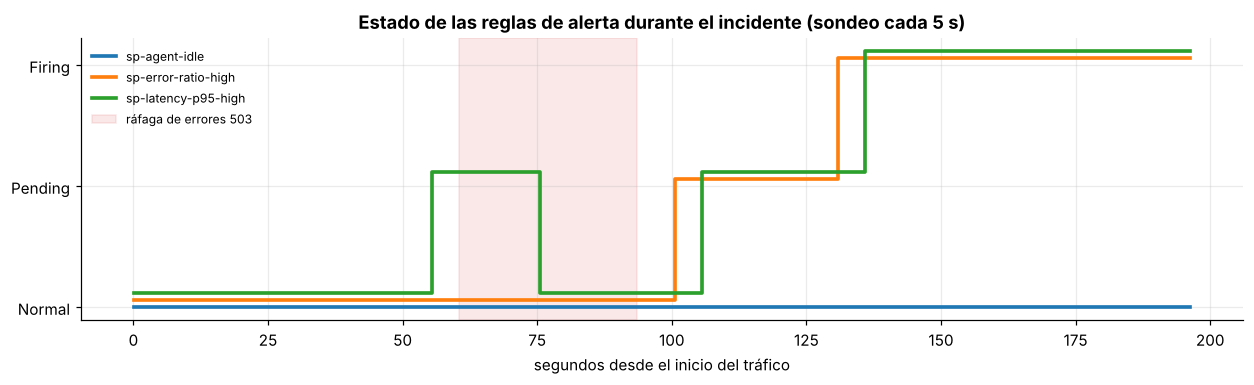

{'sp-agent-idle': {'→Pending (s)': None, '→Firing (s)': None}, 'sp-error-ratio-high': {'→Pending (s)': 101, '→Firing (s)': 131}, 'sp-latency-p95-high': {'→Pending (s)': 55, '→Firing (s)': 136}}


In [24]:
if LIVE:
    time.sleep(60); stop.set(); th.join(timeout=10)
    A = pd.DataFrame(ALERT_STATES, columns=["t", "uid", "estado"]); A["s"] = A.t - T0
    code_ = {"inactive": 0, "normal": 0, "pending": 1, "firing": 2, "alerting": 2, "nodata": 3, "error": 4}
    fig, ax = plt.subplots(figsize=(11.5, 3.6))
    for i, (uid, g) in enumerate(A.groupby("uid")):
        y = g.estado.str.lower().map(code_).fillna(0)
        ax.step(g.s, y + i * 0.06, where="post", lw=2.4, label=uid)
    ax.axvspan(SECS * 0.55, SECS * 0.85, color=viz.PALETTE["error"], alpha=.12, label="ráfaga de errores 503")
    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["Normal", "Pending", "Firing"]); ax.set_xlabel("segundos desde el inicio del tráfico"); ax.legend(fontsize=8, loc="upper left")
    ax.set_title("Estado de las reglas de alerta durante el incidente (sondeo cada 5 s)"); plt.tight_layout(); plt.show()
    first = {u: (g[g.estado.str.lower().isin(["pending"])].s.min(), g[g.estado.str.lower().isin(["firing", "alerting"])].s.min()) for u, g in A.groupby("uid")}
    print({u: {"→Pending (s)": None if np.isnan(a) else round(a), "→Firing (s)": None if np.isnan(b) else round(b)} for u, (a, b) in first.items()})

> 👀 **Qué debes observar**
>
> - Las reglas **no saltan al instante**: primero *Pending* (la condición se cumple, pero aún no durante `for`) y solo después *Firing*. El retardo total desde que empiezan los errores incluye: exportación del SDK (5 s) + *scrape* (15 s) + ventana `[2m]` del `rate` (hay que acumular errores suficientes para pasar del 10 %) + evaluación (10 s) + `for` (30 s).
> - Tras terminar la ráfaga la alerta **no se resuelve de golpe**: el `rate(...[2m])` sigue «recordando» los errores hasta 2 min después. Elegir la ventana es elegir entre **reaccionar rápido** (ventana corta, más ruido) y **estabilidad**.
> - La regla pausada (`sp-agent-idle`) y las que no se cumplen se quedan en *Normal*.

In [25]:
if LIVE:
    al = dk.grafana("GET", "/api/alertmanager/grafana/api/v2/alerts")
    show = [{"alerta": a["labels"].get("alertname"), "severity": a["labels"].get("severity"), "estado": a["status"]["state"], "receptores": [r["name"] for r in a.get("receivers", [])],
             "resumen": a["annotations"].get("summary"), "descripción (plantilla ya renderizada)": a["annotations"].get("description", "")[:110]} for a in al]
    print(f"{len(al)} alertas en el Alertmanager de Grafana")
    display(pd.DataFrame(show) if show else pd.DataFrame([{"alerta": "(ninguna activa ahora: ya se resolvieron)"}]))

2 alertas en el Alertmanager de Grafana


,alerta,severity,estado,receptores,resumen,descripción (plantilla ya renderizada)
0,SupportOps · p95 del agente alto,ticket,active,[supportops-oncall],p95 del agente por encima de 6 s,El p95 de invoke_agent de los últimos 2 min es 7s. Revisa si el LLM o una herramienta es la lent...
1,SupportOps · tasa de error alta,page,active,[supportops-oncall],Más del 10 % de los tickets terminan en error,La tasa de error de los últimos 2 min es 66.67%. Mira el panel «Trazas con error» del dashboard ...


Las anotaciones se renderizan con **plantillas** (`{{ humanizePercentage $values.B.Value }}`): el texto que recibe el on-call lleva el **valor real** que disparó la regla. Y `receptores` confirma que la política enruta al contact point `supportops-oncall` (un webhook hacia el endpoint de salud del Collector: en el laboratorio la notificación **sí se entrega** sin servicios externos; en producción sería PagerDuty, Slack o e-mail, con sus claves en un gestor de secretos y **nunca** en el repositorio).

---
# 🏭 En producción

- **Dashboards como producto:** la guía de buenas prácticas de Grafana describe tres niveles de madurez; el alto implica **JSON en control de versiones, dashboards generados con scripts, sin edición en el navegador**, experimentación en una instancia aparte y *reducción activa del sprawl* (revisar y retirar dashboards). Cada dashboard debe **estar enlazado desde una alerta**: el *browsing* debe ser la excepción.
- **Alertas:** sintomáticas (RED), con *runbook*, enlace al panel, severidad que **enruta** (página vs. ticket) y política con `group_by` para no inundar al on-call. Revisa periódicamente las alertas que nunca disparan o que siempre disparan (*alert fatigue*).
- **Provisioning en equipo:** carpetas por equipo, permisos por carpeta, `allowUiUpdates: false`, CI que ejecuta `lint` + `query_check`, y entornos (dev/stage/prod) con el **datasource como variable** para reutilizar el mismo JSON.
- **Escala:** muchos dashboards con refresco de 5 s multiplican las consultas a Prometheus/Loki/Tempo. Usa refrescos razonables, *recording rules* para las consultas pesadas del dashboard (módulo 18) y límites de consulta en el backend.

---
# 🧠 Secretos de la élite

1. **`$__rate_interval` depende de un ajuste que Grafana no puede verificar.** Es `max($__interval + scrape, 4 × scrape)` con el `timeInterval` del *datasource*; si no coincide con el *scrape* real de Prometheus, `rate()` queda sin muestras (panel vacío) o se suaviza demasiado. Lo verificamos en 4: Grafana resolvió exactamente la fórmula. Mantén el `timeInterval` del datasource **en el mismo repo** que el `scrape_interval` de Prometheus.
2. **Apilar series puede mentir.** La guía de Grafana recomienda desactivar el apilado en la mayoría de los casos. Aquí lo usamos en *Peticiones/s por estado* porque las partes **suman un todo** (los estados son excluyentes). **Nunca** apiles percentiles ni ratios.
3. **El archivo manda… hasta que alguien guarda en la UI.** Con `allowUiUpdates: true` el guardado se acepta y **diverge** del repositorio (lo reprodujimos en 7). En producción: `false` y cambios por *pull request*.
4. **El `uid` es una API.** Cambiarlo rompe enlaces (`/d/<uid>`), *dashboard links* por tag y las alertas con `dashboardUid`. Generarlo en cada build es el error más caro de «dashboards como código».
5. **Una alerta no puede usar un panel como fuente de ventana:** `$__rate_interval` no tiene panel que lo resuelva en una regla; fija la ventana (`[2m]`) y que sea **≥ 4 × scrape**. Y recuerda la cadena de retardos: exportación + *scrape* + ventana + evaluación + `for`.
6. **`noDataState` es una decisión de negocio, no un detalle.** «Sin datos» puede significar *sin tráfico* (normal en horas valle) o *telemetría caída* (grave). Por eso `sp-error-ratio-high` usa `OK` (sin tráfico = sin errores) y la regla de ausencia (`sp-agent-idle`) usa `Alerting`: las dos preguntas son distintas y **necesitan reglas distintas**. `execErrState: Error` además separa «la consulta falló» de «el sistema falló».
7. **Un YAML de alertas inválido tumba Grafana entero.** Lo vivimos construyendo esta lección: con `interval: 15s` Grafana **no arranca** («interval (15s) should be non-zero and divided exactly by scheduler interval: 10»): el intervalo de evaluación debe ser **múltiplo de 10 s**. Valida el provisioning en un Grafana efímero en CI antes de desplegar. **Provisioning de alertas es de solo lectura en la UI y reemplaza la política raíz.** La documentación lo avisa: los recursos provisionados no se editan desde Grafana, y importar uno existente da conflicto. Y `policies:` **sustituye** el árbol de notificación entero: revisa que tu política por defecto siga teniendo un receptor.
8. **Variables «All» + `=` = consultas rotas.** «All» (y multi-valor) se expande a una regex: usa `=~`, no `=`. Define `allValue: ".*"` para que «All» no genere una regex gigante con cientos de valores (más rápido y estable).
9. **Los exemplars solo se dibujan en paneles y consultas que los soportan.** Series temporales y mapas de calor con una consulta de **rango** sobre `_bucket` y `exemplar: true`. Un `histogram_quantile(...)` no tiene exemplars (ya no es un bucket). Por eso la fila 1 incluye un mapa de calor además de las líneas de percentiles.
10. **La documentación del dashboard es parte del dashboard.** Cada panel lleva `description` (qué mide, cómo leerlo, umbral); `lint` lo exige. A las 3 de la mañana, el icono «i» ahorra más tiempo que un panel extra.

---
# ⚠️ Errores comunes

| Error | Síntoma | Arreglo |
|---|---|---|
| `uid` autogenerado en cada build | Enlaces y alertas rotos tras cada despliegue | `uid` fijo y estable en el código |
| `rate(x[1m])` a mano en lugar de `$__rate_interval` | Paneles vacíos al hacer zoom | `$__rate_interval` en paneles; ventana fija ≥ 4 × scrape en alertas |
| `datasource` por nombre en el JSON | Rompe al renombrar el datasource | Referencia por **uid** (`{"type":..., "uid":...}`) |
| Variable multi-valor usada con `=` | «No data» al elegir varios valores | `=~` |
| Editar dashboards provisionados en la UI | Divergencia silenciosa | `allowUiUpdates: false` + PR |
| Alertas sobre causas (CPU de un nodo) | Ruido sin impacto en usuario | Alertas RED sobre síntomas |
| Alertas sin `runbook_url` ni enlace al panel | El on-call pierde minutos buscando | `annotations.runbook_url` + `dashboardUid`/`panelId` |
| `for: 0s` y ventanas muy cortas | Alertas que parpadean (*flapping*) | `for` ≥ 2 evaluaciones; ventana ≥ 4 × scrape |
| Contact point con secretos en el repo | Fuga de credenciales | Variables de entorno / gestor de secretos |
| Dashboard «TEST» olvidado | *Sprawl* | Prefijo `TEST:`/`TMP:` y borrado (como hicimos con `mini-demo`) |

---
# Autoevaluación

<details>
<summary>1 · **(Cálculo)** El datasource tiene `timeInterval: 15s` y el panel resuelve `$__interval` = 30 s. ¿Cuánto vale `$__rate_interval`? ¿Y si el scrape real y configurado fuera de 60 s con el mismo `$__interval`?</summary>

Con scrape 15 s: máx(30 + 15, 4·15) = máx(45, 60) = **60 s**. Con scrape 60 s: máx(30 + 60, 4·60) = máx(90, 240) = **240 s**.

</details>

<details>
<summary>2 · **(Cálculo)** Una regla se evalúa cada 10 s con `for: 30s`. El *scrape* es de 15 s, el SDK exporta cada 5 s y la ventana de la consulta es `[2m]`. ¿Cuál es el **mejor caso** de retardo entre que el primer error ocurre y la alerta pasa a *Firing*, sin contar que la tasa debe superar el umbral?</summary>

Exportación ≤ 5 s + *scrape* ≤ 15 s + una evaluación hasta ver el dato (≤ 10 s) + `for` 30 s (tres evaluaciones más): del orden de **1 minuto** en el mejor caso razonable (5 + 15 + 10 + 30 = 60 s), y más si la tasa tarda en superar el 10 % dentro de la ventana de 2 minutos.

</details>

<details>
<summary>3 · **(Cálculo)** Un dashboard tiene 4 *stats* de ancho 4 y uno de ancho 8 en una fila, y debajo 3 series de ancho 8. ¿Cuántas filas de rejilla ocupa y cuántas columnas quedan libres en la primera fila?</summary>

Primera fila: 4·4 + 8 = 24 columnas → **0 libres**, ocupa la altura del panel más alto. La segunda: 3·8 = 24 → 0 libres. (Si la suma superara 24, `Dashboard.add` salta de fila.)

</details>

<details>
<summary>4 · **(Diagnóstico)** Un panel de tasa de peticiones queda en blanco al ampliar el zoom a 1 minuto, pero con rangos largos funciona. Su consulta es `rate(x_total[30s])`. ¿Por qué y cómo se arregla?</summary>

Con *scrape* de 15 s, una ventana de 30 s contiene **2 muestras justas** (a veces 1): `rate()` necesita ≥ 2 dentro de la ventana y falla con el desfase. Arreglo: **`$__rate_interval`** (≥ 4 × scrape) y comprobar que el `timeInterval` del datasource coincide con el *scrape* real.

</details>

<details>
<summary>5 · **(Diagnóstico)** Renombras `uid: salud-agente` a `uid: salud` «por estética» y al día siguiente las alertas ya no enlazan al panel y el equipo recibe 404 en los *runbooks*. ¿Qué ha pasado y qué regla de equipo lo evita?</summary>

El `uid` es la identidad usada por los enlaces (`/d/<uid>`), las alertas (`dashboardUid`) y los *dashboard links*. Regla: **el uid es una API pública: no se cambia sin migración**; el título sí puede cambiar.

</details>

<details>
<summary>6 · **(Diagnóstico)** La regla de error no se dispara aunque el dashboard muestra un 25 % de errores. Enumera tres causas posibles.</summary>

(1) Ventana o `for` más largos que la duración del pico (la tasa en `[2m]` nunca superó el umbral el tiempo suficiente); (2) la consulta de la regla usa etiquetas distintas a las del panel (p. ej. `service_name`) y no casa; (3) `noDataState: OK` oculta que la consulta no devuelve datos; (4) la regla está pausada o el *reduce* usa `mean` en vez de `last`; (5) el intervalo de evaluación del grupo es mayor que el pico.

</details>

<details>
<summary>7 · **(Transferencia, backend/SRE)** Tienes 12 microservicios con el mismo RED. ¿Cómo evitas 12 dashboards casi idénticos y cómo conectas cada alerta con su vista?</summary>

Un **solo dashboard con variable de servicio** (`label_values(..., service_name)`), enlazado desde cada alerta con `dashboardUid` + variable en la URL; el JSON se **genera** desde código (una función `service_dashboard(service)` si necesitas variantes), con `lint`/`query_check` en CI.

</details>

<details>
<summary>8 · **(Transferencia, ML)** Quieres un dashboard de *drift* de tu agente (longitud de prompt, tasa de herramientas, calidad). ¿Qué filas pondrías y qué enlaces añadirías?</summary>

Fila 1: señales de deriva (p50/p95 de tokens de entrada hoy vs `offset 7d`, mezcla de intenciones, pasos por ticket). Fila 2: calidad online (módulo 14). Fila 3: ejemplos (trazas/logs filtrados por la versión de prompt). Enlaces: de la métrica a trazas de la versión sospechosa (atributo `supportops.release`), y a Explore con la consulta ya escrita.

</details>

---
# Referencias

**Grafana (documentación oficial, en el repositorio `grafana/grafana`)**
- Grafana, *Dashboard best practices* (RED, USE, golden signals, modelo de madurez, *sprawl*): <https://github.com/grafana/grafana/blob/main/docs/sources/visualizations/dashboards/build-dashboards/best-practices/index.md>
- Grafana, *Provision alerting resources: file provisioning* (formato de reglas, contact points, políticas): <https://github.com/grafana/grafana/blob/main/docs/sources/alerting/set-up/provision-alerting-resources/file-provisioning/index.md>
- Grafana, *Prometheus data source: template variables* (`$__rate_interval`): <https://grafana.com/docs/grafana/latest/datasources/prometheus/template-variables/>
- Grafana Labs, *New in Grafana 7.2: `$__rate_interval` for Prometheus rate queries that just work* (2020): <https://grafana.com/blog/2020/09/28/new-in-grafana-7.2-__rate_interval-for-prometheus-rate-queries-that-just-work>
- Grafana, *Correlations* (crear y provisionar): <https://grafana.com/docs/grafana/latest/administration/correlations/create-a-new-correlation/>

**Dashboards y recursos como código**
- Grafana Foundation SDK (Go, TypeScript, Python, PHP, Java): <https://github.com/grafana/grafana-foundation-sdk> · Grafonnet: <https://github.com/grafana/grafonnet> · Terraform provider: <https://github.com/grafana/terraform-provider-grafana>
- `grafanactl` (en desuso a favor de `gcx`): <https://github.com/grafana/grafanactl> · `gcx`: <https://github.com/grafana/gcx>
- KubeCon 2019, *Fool-Proof Kubernetes Dashboards for Sleep-Deprived Oncalls* (citada por la guía de Grafana): <https://www.youtube.com/watch?v=YE2aQFiMGfY>

**Método RED y señales de oro**
- Tom Wilkie, *The RED Method: How to instrument your services* (2018): <https://grafana.com/blog/2018/08/02/the-red-method-how-to-instrument-your-services>
- Beyer et al., *Site Reliability Engineering*, cap. 6: <https://sre.google/sre-book/monitoring-distributed-systems/>

> ℹ️ Versiones del laboratorio: Grafana 13.2.4, Prometheus v3.15.0, Loki 3.7.8, Tempo 3.1.0. Las páginas de grafana.com no eran accesibles desde el entorno de construcción: las citadas de grafana.com se contrastaron por fragmentos de búsqueda; la guía de buenas prácticas y el formato de provisioning de alertas se leyeron del repositorio.